# Задание на лабораторную работу №2. Pandas и основы python
## Общее задание
1. Сгенерировать с использованием библиотеки pandas csv файл, содержащий 3 столбца: $x_1$, $x_2$, $y$ (> 400 строк, генерация с использованием функции linspace). Вид функции определяется вариантом (диапазон выбирается студентом).
2. Открыть файл с использованием библиотеки pandas и построить графики: $y(x_1)$ ($x_2$ - константа), $y(x_2)$  ($x_1$ - константа). Графики необходимо построить с использованием matplotlib (для функции y отобразить точки на графике). 
3. Вывести для каждого столбца $(x_1, x_2, y)$: среднее, минимальное и максимальное значения.
4. Сохранить в новый csv файл те строки, для которых выполняется условие: $x_1$ меньше среднее $x_1$ или $x_2$ меньше среднее $x_2$
5. С использованием mplot3D построить 3D график функции $y(x_1, x_2)$ в отдельном окне.

## Вариант
12. $y = 0.01 * tan(x_1) * x_2^2$


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

**1. Генерация данных и сохранение в CSV**

In [2]:
# Задаём диапазоны для x1 и x2
x1 = np.linspace(-1, 1, 450)  # 450 точек от -1 до 1
x2 = np.linspace(0, 5, 450)

# Создаём DataFrame
df = pd.DataFrame({
    'x1': x1,
    'x2': x2,
})

# Вычисляем y по формуле
df['y'] = 0.01 * np.tan(df['x1']) * df['x2']**2

# Сохраняем данные в CSV
df.to_csv('data.csv', index=False)
df.head()

,x1,x2,y
0,-1.000000,0.000000,-0.000000
1,-0.995546,0.011136,-0.000002
2,-0.991091,0.022272,-0.000008
3,-0.986637,0.033408,-0.000017
4,-0.982183,0.044543,-0.000030


**2. Построение графиков зависимостей y(x₁) и y(x₂)**

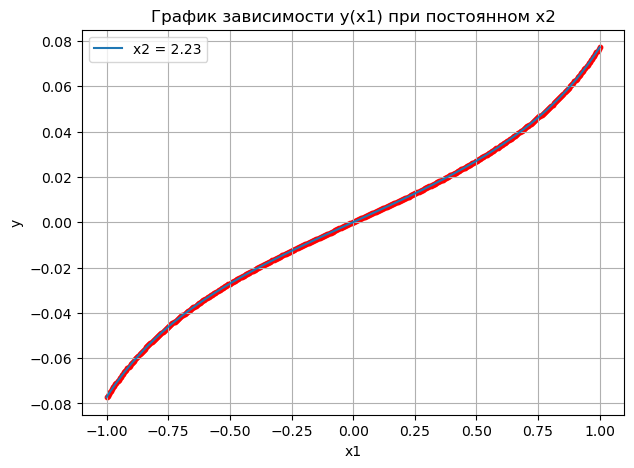

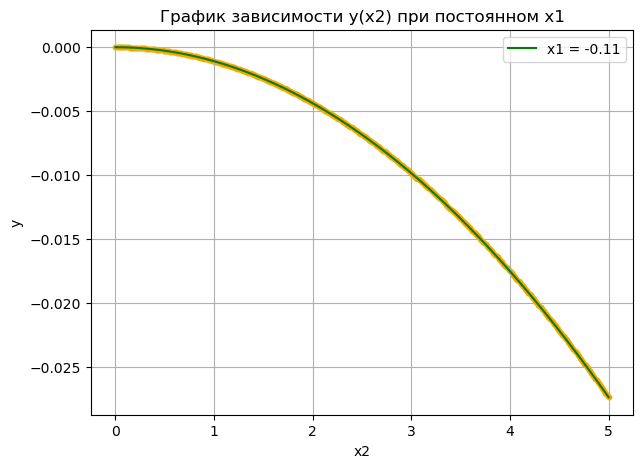

In [3]:
# График y(x1) при постоянном x2
x2_const = df['x2'].iloc[200]
y_x1 = 0.01 * np.tan(x1) * x2_const**2

plt.figure(figsize=(7, 5))
plt.plot(x1, y_x1, label=f'x2 = {x2_const:.2f}')
plt.scatter(x1, y_x1, color='red', s=10)
plt.title('График зависимости y(x1) при постоянном x2')
plt.xlabel('x1')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

# График y(x2) при постоянном x1
x1_const = df['x1'].iloc[200]
y_x2 = 0.01 * np.tan(x1_const) * x2**2

plt.figure(figsize=(7, 5))
plt.plot(x2, y_x2, label=f'x1 = {x1_const:.2f}', color='green')
plt.scatter(x2, y_x2, color='orange', s=10)
plt.title('График зависимости y(x2) при постоянном x1')
plt.xlabel('x2')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

**3. Статистика по столбцам (среднее, минимум, максимум)**

In [4]:
stats = df.describe().loc[['mean', 'min', 'max']]
print('Статистика по столбцам:')
display(stats)

Статистика по столбцам:


,x1,x2,y
mean,0.0,2.5,0.053826
min,-1.0,0.0,-0.009639
max,1.0,5.0,0.389352


**4. Фильтрация строк и сохранение нового CSV**

In [5]:
x1_mean = df['x1'].mean()
x2_mean = df['x2'].mean()

filtered_df = df[(df['x1'] < x1_mean) | (df['x2'] < x2_mean)]
filtered_df.to_csv('filtered_data.csv', index=False)
filtered_df.head()

,x1,x2,y
0,-1.000000,0.000000,-0.000000
1,-0.995546,0.011136,-0.000002
2,-0.991091,0.022272,-0.000008
3,-0.986637,0.033408,-0.000017
4,-0.982183,0.044543,-0.000030


**5. Построение 3D-графика функции y(x₁, x₂)**


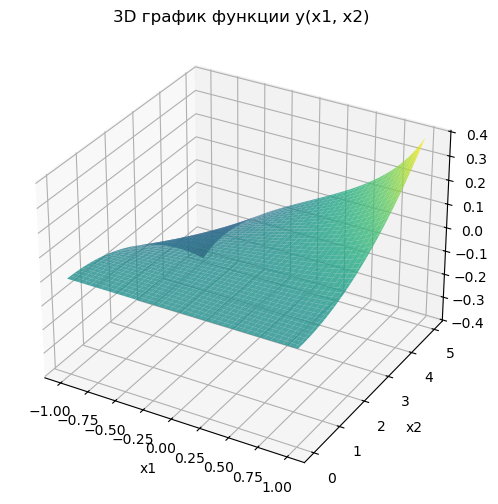

In [6]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# создаём сетку для поверхности
X1, X2 = np.meshgrid(np.linspace(-1, 1, 80), np.linspace(0, 5, 80))
Y = 0.01 * np.tan(X1) * X2**2

surf = ax.plot_surface(X1, X2, Y, cmap='viridis', alpha=0.8)
ax.set_title('3D график функции y(x1, x2)')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('y')

plt.show()